# Temporal Graph Neural Network (TGN) Memory Poisoning Detector
## All-in-One Training, Evaluation & Inference Notebook

This notebook contains the complete end-to-end pipeline for memory graph poisoning detection:
1. **Hyperparameter Configuration**: Inlined configuration dictionary matching `configs/default.yaml`.
2. **Data Pipeline**: Memory graph snapshot data loader & trajectory window batching (`MemoryTrajectoryDataset`).
3. **Model Architecture**: Complete `TGNDetector` (Node Memory Module, 2-layer GAT, Temporal GRU Aggregator, Graph & Node Anomaly Heads).
4. **Training Loop**: Phase 1 Supervised Contrastive Pre-training (`SupConLoss`) & Phase 2 Supervised Fine-tuning (`FocalLoss` + BCE).
5. **Evaluation Suite**: Graph-level AUROC, F1@0.5, AP, FPR@TPR90, Node-level AP & AUROC, and Detection Latency calculation.
6. **Inference & Interactive Visualization**: Plotting score trajectories over time and visualizing graph node predictions with NetworkX.

## 1. Setup & Environment Imports

In [1]:
import os
import sys
import json
import math
import yaml
import numpy as np
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Tuple, Optional, Dict

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torch_geometric
from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATConv
from torch_geometric.utils import softmax as scatter_softmax

import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import Patch
from tqdm.notebook import tqdm
from sklearn.metrics import (
    roc_auc_score, f1_score, average_precision_score,
    precision_recall_curve, roc_curve
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using PyTorch version: {torch.__version__}")
print(f"Using PyTorch Geometric version: {torch_geometric.__version__}")
print(f"Using device: {device}")


Using PyTorch version: 2.5.1+cu121
Using PyTorch Geometric version: 2.8.0.post1
Using device: cuda


## 2. Hyperparameters & Configuration

In [2]:
# Default Configuration Dictionary for Memory Poisoning Detection Experiments
CONFIG = {
    "api_rate_limit": 5.0,
    "simulation": {
        "num_sequences": 300,
        "interactions_per_sequence": 200,
        "memory_size_baseline": 300,
        "snapshot_interval": 10,
        "embedding_dim": 384,
        "semantic_edge_threshold": 0.6,
        "domain": "customer_support",
    },
    "attacks": {
        "types": [
            {
                "name": "minja_query_only",
                "description": "Query-only injection via bridging steps (MINJA-style)",
                "num_injected_records": 15,
                "injection_spread": 30,
                "semantic_coherence": 0.85,
            },
            {
                "name": "direct_write",
                "description": "Privileged attacker with direct memory write access",
                "num_injected_records": 10,
                "injection_spread": 1,
                "semantic_coherence": 0.90,
            },
            {
                "name": "incremental_slow",
                "description": "Low-and-slow gradual poisoning over many sessions",
                "num_injected_records": 20,
                "injection_spread": 100,
                "semantic_coherence": 0.75,
            },
        ],
        "target_neighborhood_size": 20,
        "attack_ratio": 0.4,
    },
    "model": {
        "node_feature_dim": 384,  # Input feature dimension (+3 meta features added internally)
        "node_memory_dim": 128,   # GRU memory state per node
        "gat_hidden_dim": 128,    # GAT hidden dimension
        "gat_heads": 4,           # Number of attention heads
        "gat_layers": 2,          # GAT layers
        "gru_hidden_dim": 128,    # Temporal GRU hidden dim
        "mlp_hidden_dim": 64,     # Scoring head hidden dim
        "dropout": 0.3,
    },
    "training": {
        "temporal_window": 10,
        "batch_size": 4,
        "learning_rate": 0.0001,
        "weight_decay": 0.00001,
        "epochs_contrastive": 5,
        "epochs_supervised": 10,
        "early_stopping_patience": 10,
        "gradient_clip": 1.0,
        "focal_loss_gamma": 3.0,      
        "focal_loss_alpha": 0.92,    
        "loss_alpha": 1.0,
        "loss_beta": 2.5,             
        "loss_gamma": 0.3,
        "oversample_ratio": 3,
    },
    "evaluation": {
        "metrics": ["auroc", "f1", "average_precision", "detection_latency", "fpr_at_tpr90"],
        "target_auroc": 0.85,
        "ood_auroc_drop_threshold": 0.05,
    },
    "dataset": {
        "train_ratio": 0.8,
        "val_ratio": 0.1,
        "test_ratio": 0.1,
        "seed": 42,
    }
}

# Optional: Override with configs/default.yaml if present in directory hierarchy
for yaml_path in [Path("../configs/default.yaml"), Path("configs/default.yaml")]:
    if yaml_path.exists():
        with open(yaml_path) as f:
            loaded_cfg = yaml.safe_load(f)
            if loaded_cfg:
                CONFIG.update(loaded_cfg)
                print(f"Loaded override configuration from {yaml_path}")
        break
else:
    print("Using embedded default hyperparameters configuration.")

Loaded override configuration from ..\configs\default.yaml


## 3. Data Types & Memory Trajectory Dataset

In [3]:
@dataclass
class MemoryRecord:
    """A single memory record (node in the graph)."""
    record_id: int
    embedding: np.ndarray
    timestamp: int
    retrieval_count: int = 0
    last_retrieved: int = 0
    provenance: str = "user"
    is_poisoned: bool = False
    semantic_cluster: int = 0


@dataclass
class GraphSnapshot:
    """A snapshot of the memory graph at time t."""
    timestamp: int
    node_ids: List[int]
    node_features: np.ndarray       # (num_nodes, feature_dim)
    edge_index: np.ndarray          # (2, num_edges)
    edge_weights: np.ndarray        # (num_edges,)
    node_labels: np.ndarray         # (num_nodes,) 0=benign, 1=poisoned
    graph_label: int                # 0=clean, 1=poisoned at this timestep


_DEFAULT_EMBEDDING_DIM = 384
_DEFAULT_META_FEATURES = 3  # recency, retrieval_freq, retrieval_recency


class MemoryTrajectoryDataset(Dataset):
    """
    Dataset of memory graph trajectories.
    Each item is a sequence of T graph snapshots forming a temporal window.
    """

    def __init__(self, data_dir: str, split: str = "train", temporal_window: int = 10,
                 embedding_dim: int = _DEFAULT_EMBEDDING_DIM,
                 sequence_ids: Optional[List[str]] = None):
        self.data_dir = Path(data_dir)
        self.temporal_window = temporal_window
        self.feature_dim = embedding_dim + _DEFAULT_META_FEATURES

        # Load metadata
        with open(self.data_dir / "metadata.json") as f:
            metadata = json.load(f)
        self.metadata = {m["sequence_id"]: m for m in metadata}

        if sequence_ids is not None:
            # Explicit override (e.g. attack-type holdout filtering) bypasses splits.json.
            self.sequence_ids = sequence_ids
        else:
            with open(self.data_dir / "splits.json") as f:
                splits = json.load(f)
            self.sequence_ids = splits[split]

        # Build index of all valid temporal windows
        self.windows = self._build_window_index()

    def _build_window_index(self) -> List[Tuple[str, int]]:
        windows = []
        for seq_id in self.sequence_ids:
            seq_dir = self.data_dir / seq_id
            if not seq_dir.exists():
                continue
            num_snapshots = len(list(seq_dir.glob("snapshot_*.npz")))
            for start in range(max(1, num_snapshots - self.temporal_window + 1)):
                windows.append((seq_id, start))
        return windows

    def __len__(self) -> int:
        return len(self.windows)

    def __getitem__(self, idx: int) -> dict:
        seq_id, start = self.windows[idx]
        seq_dir = self.data_dir / seq_id

        graphs = []
        for i in range(start, start + self.temporal_window):
            snap_path = seq_dir / f"snapshot_{i:04d}.npz"
            if snap_path.exists():
                graphs.append(self._load_snapshot(snap_path))
            else:
                graphs.append(self._empty_graph())

        last_graph = graphs[-1]
        graph_label = last_graph.y.item()
        node_labels = last_graph.node_labels

        return {
            "graphs": graphs,              # List of T PyG Data objects
            "graph_label": graph_label,    # 0 or 1
            "node_labels": node_labels,    # Per-node labels at final timestep
            "sequence_id": seq_id,
            "window_start": start,
        }

    def _load_snapshot(self, path: Path) -> Data:
        snap = np.load(path)

        node_features = torch.tensor(snap["node_features"], dtype=torch.float32)
        edge_index = torch.tensor(snap["edge_index"], dtype=torch.long)
        edge_weights = torch.tensor(snap["edge_weights"], dtype=torch.float32)
        node_labels = torch.tensor(snap["node_labels"], dtype=torch.long)
        graph_label = torch.tensor(snap["graph_label"], dtype=torch.long).squeeze()

        if edge_weights.numel() > 0:
            edge_attr = edge_weights.unsqueeze(-1)
        else:
            edge_attr = torch.zeros((0, 1), dtype=torch.float32)

        num_nodes = node_features.size(0)
        node_ids = torch.arange(num_nodes, dtype=torch.long)

        return Data(
            x=node_features,
            edge_index=edge_index,
            edge_attr=edge_attr,
            y=graph_label,
            node_labels=node_labels,
            node_ids=node_ids,
        )

    def _empty_graph(self) -> Data:
        return Data(
            x=torch.zeros((1, self.feature_dim), dtype=torch.float32),
            edge_index=torch.zeros((2, 0), dtype=torch.long),
            edge_attr=torch.zeros((0, 1), dtype=torch.float32),
            y=torch.tensor(0, dtype=torch.long),
            node_labels=torch.zeros(1, dtype=torch.long),
            node_ids=torch.zeros(1, dtype=torch.long),
        )


def collate_trajectories(batch: List[dict]) -> dict:
    T = len(batch[0]["graphs"])
    batched_graphs = []
    for t in range(T):
        graphs_at_t = [item["graphs"][t] for item in batch]
        batched_graphs.append(Batch.from_data_list(graphs_at_t))

    graph_labels = torch.tensor([item["graph_label"] for item in batch], dtype=torch.float32)

    return {
        "graphs": batched_graphs,
        "graph_labels": graph_labels,
        "sequence_ids": [item["sequence_id"] for item in batch],
    }


## 4. TGN Model Architecture (`TGNDetector`)
The network consists of:
- **Node Memory Module**: GRU cell persistent per `node_id` across sequence timesteps.
- **Graph Encoder**: 2-layer Graph Attention Network (GAT) with cosine similarity edge attributes.
- **Temporal Aggregator**: GRU over graph pooled embeddings across T timesteps.
- **Scoring Heads**: Graph-level anomaly MLP and Node-level anomaly MLP.

In [4]:
class NodeMemoryModule(nn.Module):
    """GRU cell that maintains per-node memory state over interaction time."""

    def __init__(self, input_dim: int, memory_dim: int):
        super().__init__()
        self.memory_dim = memory_dim
        self.gru_cell = nn.GRUCell(input_dim, memory_dim)

    def forward(self, node_features: torch.Tensor, prev_memory: Optional[torch.Tensor] = None) -> torch.Tensor:
        if prev_memory is None:
            prev_memory = torch.zeros(node_features.size(0), self.memory_dim, device=node_features.device)
        return self.gru_cell(node_features, prev_memory)


class GraphEncoder(nn.Module):
    """2-layer GAT that produces node embeddings from the memory graph."""

    def __init__(self, input_dim: int, hidden_dim: int, num_heads: int = 4,
                 dropout: float = 0.3, edge_dim: int = 1):
        super().__init__()
        self.gat1 = GATConv(
            input_dim, hidden_dim, heads=num_heads, dropout=dropout,
            concat=True, edge_dim=edge_dim,
        )
        self.gat2 = GATConv(
            hidden_dim * num_heads, hidden_dim, heads=1, dropout=dropout,
            concat=False, edge_dim=edge_dim,
        )
        self.dropout = dropout

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor,
                edge_attr: Optional[torch.Tensor] = None) -> torch.Tensor:
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.gat1(x, edge_index, edge_attr=edge_attr))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.gat2(x, edge_index, edge_attr=edge_attr)
        return x


class AttentionPool(nn.Module):
    """Learned attention pooling over nodes in a graph (Ilse et al. MIL-style attention).

    Plain mean pooling averages a small anomalous subgraph (e.g. ~15-20 poisoned
    nodes among hundreds of benign ones) away almost by construction. This lets the
    graph-level readout instead learn to up-weight the nodes that matter.
    """

    def __init__(self, input_dim: int, hidden_dim: int = 64):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x: torch.Tensor, batch_idx: torch.Tensor, num_graphs: Optional[int] = None) -> torch.Tensor:
        scores = self.attn(x).squeeze(-1)
        weights = scatter_softmax(scores, batch_idx)
        weighted = x * weights.unsqueeze(-1)
        if num_graphs is None:
            num_graphs = int(batch_idx.max().item()) + 1 if batch_idx.numel() > 0 else 0
        out = weighted.new_zeros(num_graphs, x.size(-1))
        out = out.index_add(0, batch_idx, weighted)
        return out


class TemporalAggregator(nn.Module):
    """GRU that reads sequence of graph-level embeddings over T timesteps."""

    def __init__(self, input_dim: int, hidden_dim: int):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True)

    def forward(self, graph_sequence: torch.Tensor) -> torch.Tensor:
        output, h_n = self.gru(graph_sequence)
        return h_n.squeeze(0)


class GraphAnomalyHead(nn.Module):
    """MLP that scores graph-level anomaly probability."""

    def __init__(self, input_dim: int, hidden_dim: int):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, h: torch.Tensor) -> torch.Tensor:
        return torch.sigmoid(self.mlp(h)).squeeze(-1)


class NodeAnomalyHead(nn.Module):
    """MLP that scores per-node anomaly probability."""

    def __init__(self, node_dim: int, traj_dim: int, hidden_dim: int):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(node_dim + traj_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, node_embeddings: torch.Tensor, trajectory_emb: torch.Tensor, batch_idx: torch.Tensor) -> torch.Tensor:
        traj_per_node = trajectory_emb[batch_idx]  # Broadcast trajectory to each node
        combined = torch.cat([node_embeddings, traj_per_node], dim=-1)
        return torch.sigmoid(self.mlp(combined)).squeeze(-1)


class TGNDetector(nn.Module):
    """
    Full Temporal GNN Detector for Memory Poisoning.
    """

    def __init__(self, config: dict):
        super().__init__()
        model_cfg = config["model"]

        input_dim = model_cfg["node_feature_dim"] + 3
        memory_dim = model_cfg["node_memory_dim"]
        gat_hidden = model_cfg["gat_hidden_dim"]
        gat_heads = model_cfg["gat_heads"]
        gru_hidden = model_cfg["gru_hidden_dim"]
        mlp_hidden = model_cfg["mlp_hidden_dim"]
        dropout = model_cfg["dropout"]

        self.node_memory = NodeMemoryModule(input_dim, memory_dim)
        self.graph_encoder = GraphEncoder(
            input_dim=input_dim + memory_dim,
            hidden_dim=gat_hidden,
            num_heads=gat_heads,
            dropout=dropout,
            edge_dim=1,
        )
        self.attn_pool = AttentionPool(input_dim=gat_hidden, hidden_dim=mlp_hidden)
        self.temporal_aggregator = TemporalAggregator(
            input_dim=gat_hidden,
            hidden_dim=gru_hidden,
        )
        self.graph_head = GraphAnomalyHead(gru_hidden, mlp_hidden)
        self.node_head = NodeAnomalyHead(gat_hidden, gru_hidden, mlp_hidden)

        self.gat_hidden = gat_hidden
        self.gru_hidden = gru_hidden
        self.memory_dim = memory_dim
        self._memory_tensor: Optional[torch.Tensor] = None

    def reset_memory(self):
        self._memory_tensor = None

    def _ensure_memory_tensor(self, required_size: int, device: torch.device):
        if self._memory_tensor is None or self._memory_tensor.size(0) < required_size:
            alloc_size = max(required_size, (self._memory_tensor.size(0) * 2) if self._memory_tensor is not None else 1000)
            new_tensor = torch.zeros(alloc_size, self.memory_dim, device=device)
            if self._memory_tensor is not None:
                new_tensor[:self._memory_tensor.size(0)] = self._memory_tensor
            self._memory_tensor = new_tensor

    def _get_node_memories(self, node_ids: torch.Tensor, device: torch.device) -> torch.Tensor:
        if node_ids is None or node_ids.numel() == 0:
            return torch.zeros(0, self.memory_dim, device=device)

        max_id = int(node_ids.max().item()) + 1
        self._ensure_memory_tensor(max_id, device)
        return self._memory_tensor[node_ids]

    def _store_node_memories(self, node_ids: torch.Tensor, memories: torch.Tensor):
        if node_ids is None or node_ids.numel() == 0:
            return

        max_id = int(node_ids.max().item()) + 1
        self._ensure_memory_tensor(max_id, memories.device)
        self._memory_tensor[node_ids] = memories.detach()

    def forward(self, graph_sequence: List[Batch]) -> Tuple[torch.Tensor, torch.Tensor]:
        T = len(graph_sequence)
        graph_embeddings = []
        last_node_embeddings = None
        last_batch_idx = None

        self.reset_memory()

        for t in range(T):
            g = graph_sequence[t]
            x = g.x
            edge_index = g.edge_index
            batch_idx = g.batch
            edge_attr = g.edge_attr if hasattr(g, 'edge_attr') and g.edge_attr is not None else None

            if hasattr(g, 'node_ids') and g.node_ids is not None:
                prev_memory = self._get_node_memories(g.node_ids, x.device)
            else:
                prev_memory = None

            node_mem = self.node_memory(x, prev_memory)

            if hasattr(g, 'node_ids') and g.node_ids is not None:
                self._store_node_memories(g.node_ids, node_mem)

            gat_input = torch.cat([x, node_mem], dim=-1)
            node_embeddings = self.graph_encoder(gat_input, edge_index, edge_attr=edge_attr)
            num_graphs = g.num_graphs if hasattr(g, "num_graphs") else None
            graph_emb = self.attn_pool(node_embeddings, batch_idx, num_graphs=num_graphs)
            graph_embeddings.append(graph_emb)

            if t == T - 1:
                last_node_embeddings = node_embeddings
                last_batch_idx = batch_idx

        graph_seq_tensor = torch.stack(graph_embeddings, dim=1)
        trajectory_emb = self.temporal_aggregator(graph_seq_tensor)
        graph_scores = self.graph_head(trajectory_emb)
        node_scores = self.node_head(last_node_embeddings, trajectory_emb, last_batch_idx)

        return graph_scores, node_scores

    def get_trajectory_embedding(self, graph_sequence: List[Batch]) -> torch.Tensor:
        T = len(graph_sequence)
        graph_embeddings = []
        self.reset_memory()

        for t in range(T):
            g = graph_sequence[t]
            x = g.x
            edge_index = g.edge_index
            batch_idx = g.batch
            edge_attr = g.edge_attr if hasattr(g, 'edge_attr') and g.edge_attr is not None else None

            if hasattr(g, 'node_ids') and g.node_ids is not None:
                prev_memory = self._get_node_memories(g.node_ids, x.device)
            else:
                prev_memory = None

            node_mem = self.node_memory(x, prev_memory)

            if hasattr(g, 'node_ids') and g.node_ids is not None:
                self._store_node_memories(g.node_ids, node_mem)

            gat_input = torch.cat([x, node_mem], dim=-1)
            node_embeddings = self.graph_encoder(gat_input, edge_index, edge_attr=edge_attr)
            num_graphs = g.num_graphs if hasattr(g, "num_graphs") else None
            graph_emb = self.attn_pool(node_embeddings, batch_idx, num_graphs=num_graphs)
            graph_embeddings.append(graph_emb)

        graph_seq_tensor = torch.stack(graph_embeddings, dim=1)
        return self.temporal_aggregator(graph_seq_tensor)


## 5. Loss Functions & Training Class

In [5]:
def set_seed(seed: int = 42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class FocalLoss(nn.Module):
    def __init__(self, gamma: float = 2.0, alpha: float = 0.75):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha

    def forward(self, pred: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        bce = F.binary_cross_entropy(pred, target.float(), reduction="none")
        pt = torch.where(target == 1, pred, 1 - pred)
        alpha_t = torch.where(target == 1, self.alpha, 1 - self.alpha)
        focal = alpha_t * (1 - pt) ** self.gamma * bce
        return focal.mean()


class SupConLoss(nn.Module):
    def __init__(self, temperature: float = 0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, features: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
        batch_size = features.size(0)
        if batch_size < 2:
            # Disconnected zero would crash .backward() (no grad_fn); keep it
            # attached to the graph so this batch just contributes zero grad.
            return features.sum() * 0.0

        features = F.normalize(features, dim=1)
        sim = torch.mm(features, features.t()) / self.temperature
        self_mask = torch.eye(batch_size, dtype=torch.bool, device=features.device)
        sim = sim.masked_fill(self_mask, -1e9)

        labels = labels.view(-1, 1)
        pos_mask = (labels == labels.t()) & ~self_mask

        if pos_mask.sum() == 0:
            return features.sum() * 0.0

        log_prob = sim - torch.logsumexp(sim, dim=1, keepdim=True)
        mean_log_prob_pos = (pos_mask * log_prob).sum(1) / pos_mask.sum(1).clamp(min=1)
        return -mean_log_prob_pos.mean()


def apply_embedding_noise_augment(graphs: list, prob: float, sigma_max: float,
                                   embedding_dim: int = 384) -> list:
    """Randomly perturbs node text embeddings (in place on cloned tensors) for a
    fraction of training batches. Sigma is sampled per-batch from U(0, sigma_max).
    Edge structure, node_ids, and labels are untouched - only meant to stop the
    model from relying on exact, noise-free embedding coordinates."""
    import random
    if random.random() >= prob:
        return graphs
    sigma = random.uniform(0.0, sigma_max)
    if sigma <= 0.0:
        return graphs
    for g in graphs:
        g.x = g.x.clone()
        noise = torch.randn_like(g.x[:, :embedding_dim]) * sigma
        g.x[:, :embedding_dim] = g.x[:, :embedding_dim] + noise
    return graphs


class Trainer:
    def __init__(self, config: dict, data_dir: str, device: torch.device,
                 holdout_attack_type: Optional[str] = None,
                 noise_augment_prob: float = 0.0, noise_sigma_max: float = 0.1):
        self.config = config
        self.train_cfg = config["training"]
        self.data_dir = Path(data_dir)
        self.device = device
        self.noise_augment_prob = noise_augment_prob
        self.noise_sigma_max = noise_sigma_max

        self.model = TGNDetector(config).to(self.device)
        print(f"Model parameters: {sum(p.numel() for p in self.model.parameters()):,}")

        T = self.train_cfg["temporal_window"]
        embedding_dim = config["simulation"]["embedding_dim"]

        train_ids, val_ids, holdout_ids = self._build_splits(holdout_attack_type)
        self.holdout_ids = holdout_ids

        self.train_dataset = MemoryTrajectoryDataset(
            data_dir, temporal_window=T, embedding_dim=embedding_dim, sequence_ids=train_ids)
        self.val_dataset = MemoryTrajectoryDataset(
            data_dir, temporal_window=T, embedding_dim=embedding_dim, sequence_ids=val_ids)
        self.holdout_dataset = None
        if holdout_ids:
            self.holdout_dataset = MemoryTrajectoryDataset(
                data_dir, temporal_window=T, embedding_dim=embedding_dim, sequence_ids=holdout_ids)

        self.train_loader = DataLoader(
            self.train_dataset, batch_size=self.train_cfg["batch_size"],
            shuffle=True, collate_fn=collate_trajectories,
        )
        self.val_loader = DataLoader(
            self.val_dataset, batch_size=self.train_cfg["batch_size"],
            shuffle=False, collate_fn=collate_trajectories,
        )
        self.holdout_loader = None
        if self.holdout_dataset is not None:
            self.holdout_loader = DataLoader(
                self.holdout_dataset, batch_size=self.train_cfg["batch_size"],
                shuffle=False, collate_fn=collate_trajectories,
            )

        self.graph_loss_fn = nn.BCELoss()
        self.node_loss_fn = FocalLoss(gamma=self.train_cfg["focal_loss_gamma"],
                                       alpha=self.train_cfg.get("focal_loss_alpha", 0.75))
        self.contrastive_loss_fn = SupConLoss()

        self.optimizer = torch.optim.Adam(
            self.model.parameters(), lr=self.train_cfg["learning_rate"],
            weight_decay=self.train_cfg["weight_decay"],
        )
        self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            self.optimizer, T_max=self.train_cfg["epochs_supervised"]
        )

    def _build_splits(self, holdout_attack_type: Optional[str]):
        with open(self.data_dir / "splits.json") as f:
            splits = json.load(f)
        with open(self.data_dir / "metadata.json") as f:
            metadata = {m["sequence_id"]: m for m in json.load(f)}

        if not holdout_attack_type:
            return splits["train"], splits["val"], []

        def is_holdout(seq_id):
            return metadata[seq_id].get("attack_type") == holdout_attack_type

        train_ids = [s for s in splits["train"] if not is_holdout(s)]
        val_ids = [s for s in splits["val"] if not is_holdout(s)]
        holdout_ids = [s for s in (splits["train"] + splits["val"] + splits["test"]) if is_holdout(s)]

        n_removed = (len(splits["train"]) - len(train_ids)) + (len(splits["val"]) - len(val_ids))
        print(f"Holdout attack type '{holdout_attack_type}': removed {n_removed} sequences from "
              f"train/val, {len(holdout_ids)} sequences reserved for generalization eval.")
        return train_ids, val_ids, holdout_ids

    def train_phase1_contrastive(self, save_dir: str):
        print("\n=== Phase 1: Supervised Contrastive Pre-training ===")
        epochs = self.train_cfg["epochs_contrastive"]
        patience = self.train_cfg["early_stopping_patience"]
        best_loss = float("inf")
        no_improve = 0

        phase1_optimizer = torch.optim.Adam(
            self.model.parameters(), lr=self.train_cfg["learning_rate"],
            weight_decay=self.train_cfg["weight_decay"],
        )
        phase1_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(phase1_optimizer, T_max=epochs)

        for epoch in range(epochs):
            self.model.train()
            total_loss = 0
            num_batches = 0

            for batch in tqdm(self.train_loader, desc=f"Phase 1 Epoch {epoch+1}/{epochs}"):
                graphs = [g.to(self.device) for g in batch["graphs"]]
                labels = batch["graph_labels"].to(self.device)

                if labels.size(0) < 2:
                    continue

                embeddings = self.model.get_trajectory_embedding(graphs)
                loss = self.contrastive_loss_fn(embeddings, labels)

                phase1_optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.train_cfg["gradient_clip"])
                phase1_optimizer.step()

                total_loss += loss.item()
                num_batches += 1
                if self.device.type == "cuda":
                    torch.cuda.empty_cache()

            phase1_scheduler.step()
            avg_loss = total_loss / max(num_batches, 1)
            print(f"  Epoch {epoch+1}: Contrastive Loss = {avg_loss:.4f}")

            if avg_loss < best_loss:
                best_loss = avg_loss
                no_improve = 0
                torch.save(self.model.state_dict(), Path(save_dir) / "phase1_best.pt")
            else:
                no_improve += 1
                if no_improve >= patience:
                    print(f"  Early stopping at epoch {epoch+1}")
                    break

    def train_phase2_supervised(self, save_dir: str):
        print("\n=== Phase 2: Supervised Fine-tuning ===")
        print(f"  Embedding-noise augmentation: prob={self.noise_augment_prob}, sigma_max={self.noise_sigma_max}")
        epochs = self.train_cfg["epochs_supervised"]
        patience = self.train_cfg["early_stopping_patience"]
        alpha = self.train_cfg["loss_alpha"]
        beta = self.train_cfg["loss_beta"]

        best_val_loss = float("inf")
        no_improve = 0
        history = {"train_loss": [], "val_loss": [], "val_auroc": [], "val_node_auroc": []}

        for epoch in range(epochs):
            self.model.train()
            train_loss = self._train_epoch(alpha, beta, epoch, epochs)
            history["train_loss"].append(train_loss)

            val_loss, val_auroc, val_node_auroc = self._evaluate(self.val_loader, alpha, beta)
            history["val_loss"].append(val_loss)
            history["val_auroc"].append(val_auroc)
            history["val_node_auroc"].append(val_node_auroc)

            self.scheduler.step()

            print(f"  Epoch {epoch+1}/{epochs}: "
                  f"Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}, "
                  f"Val AUROC={val_auroc:.4f}, Val Node AUROC={val_node_auroc:.4f}")

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                no_improve = 0
                torch.save(self.model.state_dict(), Path(save_dir) / "phase2_best.pt")
            else:
                no_improve += 1
                if no_improve >= patience:
                    print(f"  Early stopping at epoch {epoch+1}")
                    break

        torch.save(self.model.state_dict(), Path(save_dir) / "phase2_final.pt")
        with open(Path(save_dir) / "training_history.json", "w") as f:
            json.dump(history, f, indent=2)

        print(f"  Models saved to {save_dir}")

    def _train_epoch(self, alpha: float, beta: float, epoch: int, epochs: int) -> float:
        self.model.reset_memory()
        total_loss = 0
        num_batches = 0

        for batch in tqdm(self.train_loader, desc=f"Phase 2 Epoch {epoch+1}/{epochs}", leave=False):
            graphs = [g.to(self.device) for g in batch["graphs"]]
            graphs = apply_embedding_noise_augment(graphs, self.noise_augment_prob, self.noise_sigma_max)
            graph_labels = batch["graph_labels"].to(self.device)

            graph_scores, node_scores = self.model(graphs)
            l_graph = self.graph_loss_fn(graph_scores, graph_labels)

            last_graph = graphs[-1]
            if hasattr(last_graph, "node_labels"):
                node_labels = last_graph.node_labels.to(self.device).float()
                min_len = min(node_scores.size(0), node_labels.size(0))
                l_node = self.node_loss_fn(node_scores[:min_len], node_labels[:min_len])
            else:
                l_node = torch.tensor(0.0, device=self.device)

            loss = alpha * l_graph + beta * l_node

            self.optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.train_cfg["gradient_clip"])
            self.optimizer.step()

            total_loss += loss.item()
            num_batches += 1
            if self.device.type == "cuda":
                torch.cuda.empty_cache()

        return total_loss / max(num_batches, 1)

    @torch.no_grad()
    def _evaluate(self, loader: DataLoader, alpha: float, beta: float) -> tuple:
        self.model.eval()
        self.model.reset_memory()
        total_loss = 0
        num_batches = 0
        all_graph_scores, all_graph_labels = [], []
        all_node_scores, all_node_labels = [], []

        for batch in loader:
            graphs = [g.to(self.device) for g in batch["graphs"]]
            graph_labels = batch["graph_labels"].to(self.device)

            graph_scores, node_scores = self.model(graphs)
            l_graph = self.graph_loss_fn(graph_scores, graph_labels)

            last_graph = graphs[-1]
            if hasattr(last_graph, "node_labels"):
                node_labels_t = last_graph.node_labels.to(self.device).float()
                min_len = min(node_scores.size(0), node_labels_t.size(0))
                l_node = self.node_loss_fn(node_scores[:min_len], node_labels_t[:min_len])
                all_node_scores.extend(node_scores[:min_len].cpu().numpy())
                all_node_labels.extend(node_labels_t[:min_len].cpu().numpy())
            else:
                l_node = torch.tensor(0.0, device=self.device)

            total_loss += (alpha * l_graph + beta * l_node).item()
            num_batches += 1

            all_graph_scores.extend(graph_scores.cpu().numpy())
            all_graph_labels.extend(graph_labels.cpu().numpy())

            if self.device.type == "cuda":
                torch.cuda.empty_cache()

        avg_loss = total_loss / max(num_batches, 1)

        all_graph_scores = np.array(all_graph_scores)
        all_graph_labels = np.array(all_graph_labels)
        graph_auroc = (roc_auc_score(all_graph_labels, all_graph_scores)
                       if len(np.unique(all_graph_labels)) > 1 else 0.0)

        all_node_scores = np.array(all_node_scores)
        all_node_labels = np.array(all_node_labels)
        node_auroc = (roc_auc_score(all_node_labels, all_node_scores)
                      if len(all_node_labels) > 0 and len(np.unique(all_node_labels)) > 1 else 0.0)

        return avg_loss, graph_auroc, node_auroc

    def evaluate_holdout(self) -> Optional[dict]:
        """Only meaningful if this Trainer was built with holdout_attack_type set -
        reports AUROC on an attack type the model never trained on."""
        if self.holdout_loader is None:
            return None
        alpha = self.train_cfg["loss_alpha"]
        beta = self.train_cfg["loss_beta"]
        loss, graph_auroc, node_auroc = self._evaluate(self.holdout_loader, alpha, beta)
        return {"loss": loss, "graph_auroc": graph_auroc, "node_auroc": node_auroc,
                "n_sequences": len(self.holdout_ids)}


# NOTE: this notebook references an already-trained checkpoint (see EXP_DIR below)
# rather than retraining here. To actually run training, instantiate and call e.g.:
#   trainer = Trainer(CONFIG, str(DATA_DIR), device, noise_augment_prob=0.5, noise_sigma_max=0.15)
#   trainer.train_phase1_contrastive(str(EXP_DIR))
#   trainer.train_phase2_supervised(str(EXP_DIR))
# For the --holdout-attack-type generalization experiment (excludes one attack type
# entirely from train/val, then reports evaluate_holdout()), use the standalone
# src/models/train.py CLI script.


## 6. Execute Model Training (Phase 1 & Phase 2)

In [6]:
# Determine Dataset Path
DATA_DIR = Path("../data/raw/llm_generated")
if not DATA_DIR.exists():
    DATA_DIR = Path("data/raw/llm_generated")

# Determine Output Experiment Directory
EXP_DIR = Path("../experiments/run_current_arch")
if not EXP_DIR.parent.exists():
    EXP_DIR = Path("experiments/run_current_arch")
EXP_DIR.mkdir(parents=True, exist_ok=True)

# Set seeds
set_seed(CONFIG["dataset"]["seed"])

# This notebook references the already-trained, validated checkpoint at EXP_DIR
# (see "Model Evaluation Suite" below) rather than retraining live - a full
# Phase 1 + Phase 2 run took several hours end-to-end. Flip this to True only if
# you actually want to (re)train from scratch inside the notebook.
RUN_TRAINING = False

if RUN_TRAINING:
    trainer = Trainer(CONFIG, str(DATA_DIR), device=device,
                       noise_augment_prob=0.5, noise_sigma_max=0.15)
    trainer.train_phase1_contrastive(str(EXP_DIR))
    trainer.train_phase2_supervised(str(EXP_DIR))
    print(f"\nTraining finished successfully. Model checkpoints saved in: {EXP_DIR}")
else:
    print(f"RUN_TRAINING=False - skipping training, using existing checkpoint in: {EXP_DIR}")


RUN_TRAINING=False - skipping training, using existing checkpoint in: ..\experiments\run_current_arch


## 7. Model Evaluation Suite

In [5]:
EXP_DIR = Path("../experiments/run_current_arch")
DATA_DIR = Path("../data/raw/llm_generated")

IMG_DIR = Path("../experiments/eval_images")
IMG_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:
class Evaluator:
    """Evaluates the trained detector on test set."""

    def __init__(self, config: dict, checkpoint_path: str, data_dir: str, device: torch.device):
        self.config = config
        self.device = device

        self.model = TGNDetector(config).to(self.device)
        self.model.load_state_dict(torch.load(checkpoint_path, map_location=self.device, weights_only=True))
        self.model.eval()

        T = config["training"]["temporal_window"]
        embedding_dim = config["simulation"]["embedding_dim"]
        self.test_dataset = MemoryTrajectoryDataset(data_dir, split="test", temporal_window=T, embedding_dim=embedding_dim)
        self.test_loader = DataLoader(
            self.test_dataset,
            batch_size=config["training"]["batch_size"],
            shuffle=False,
            collate_fn=collate_trajectories,
        )

    @torch.no_grad()
    def evaluate_graph_level(self) -> dict:
        self.model.reset_memory()
        all_scores = []
        all_labels = []

        for batch in self.test_loader:
            graphs = [g.to(self.device) for g in batch["graphs"]]
            graph_labels = batch["graph_labels"]

            graph_scores, _ = self.model(graphs)

            all_scores.extend(graph_scores.cpu().numpy())
            all_labels.extend(graph_labels.numpy())

            if self.device.type == "cuda":
                torch.cuda.empty_cache()

        scores = np.array(all_scores)
        labels = np.array(all_labels)

        results = {}
        if len(np.unique(labels)) > 1:
            results["auroc"] = float(roc_auc_score(labels, scores))
        else:
            results["auroc"] = 0.0

        preds = (scores >= 0.5).astype(int)
        results["f1_at_0.5"] = float(f1_score(labels, preds))
        results["average_precision"] = float(average_precision_score(labels, scores))

        fpr, tpr, thresholds = roc_curve(labels, scores)
        idx = np.argmin(np.abs(tpr - 0.9))
        results["fpr_at_tpr_0.9"] = float(fpr[idx])

        precisions, recalls, thresholds_pr = precision_recall_curve(labels, scores)
        f1s = 2 * precisions * recalls / (precisions + recalls + 1e-8)
        best_idx = np.argmax(f1s)
        results["best_f1"] = float(f1s[best_idx])
        results["best_threshold"] = float(thresholds_pr[best_idx]) if best_idx < len(thresholds_pr) else 0.5

        return results

    @torch.no_grad()
    def evaluate_node_level(self) -> dict:
        self.model.reset_memory()
        all_node_scores = []
        all_node_labels = []

        for batch in self.test_loader:
            graphs = [g.to(self.device) for g in batch["graphs"]]
            _, node_scores = self.model(graphs)

            last_graph = graphs[-1]
            if hasattr(last_graph, "node_labels"):
                node_labels = last_graph.node_labels.cpu().numpy()
                ns = node_scores.cpu().numpy()
                min_len = min(len(ns), len(node_labels))
                all_node_scores.extend(ns[:min_len])
                all_node_labels.extend(node_labels[:min_len])

            if self.device.type == "cuda":
                torch.cuda.empty_cache()

        scores = np.array(all_node_scores)
        labels = np.array(all_node_labels)

        results = {}
        if len(np.unique(labels)) > 1:
            results["node_average_precision"] = float(average_precision_score(labels, scores))
            results["node_auroc"] = float(roc_auc_score(labels, scores))
        else:
            results["node_average_precision"] = 0.0
            results["node_auroc"] = 0.0

        return results

    @torch.no_grad()
    def evaluate_detection_latency(self) -> dict:
        data_dir = Path(self.test_dataset.data_dir)
        with open(data_dir / "metadata.json") as f:
            metadata = json.load(f)

        test_seq_ids = set(self.test_dataset.sequence_ids)
        poisoned_seqs = {m["sequence_id"] for m in metadata
                         if m["label"] == "poisoned" and m["sequence_id"] in test_seq_ids}
        latencies = []
        threshold = 0.5
        T = self.config["training"]["temporal_window"]

        for seq_id in poisoned_seqs:
            seq_dir = data_dir / seq_id
            if not seq_dir.exists():
                continue

            snapshots = sorted(seq_dir.glob("snapshot_*.npz"))
            if len(snapshots) < T:
                continue

            first_poisoned_idx = None
            for i, snap_path in enumerate(snapshots):
                snap = np.load(snap_path)
                if snap["graph_label"][0] == 1:
                    first_poisoned_idx = i
                    break

            if first_poisoned_idx is None:
                continue

            detected_idx = None
            for start in range(max(0, first_poisoned_idx - T + 1), len(snapshots) - T + 1):
                window_graphs = []
                for i in range(start, start + T):
                    snap = np.load(snapshots[i])
                    edge_weights = torch.tensor(snap["edge_weights"], dtype=torch.float32)
                    edge_attr = edge_weights.unsqueeze(-1) if edge_weights.numel() > 0 else torch.zeros((0, 1), dtype=torch.float32)
                    num_nodes = snap["node_features"].shape[0]
                    g = Data(
                        x=torch.tensor(snap["node_features"], dtype=torch.float32),
                        edge_index=torch.tensor(snap["edge_index"], dtype=torch.long),
                        edge_attr=edge_attr,
                        node_labels=torch.tensor(snap["node_labels"], dtype=torch.long),
                        node_ids=torch.arange(num_nodes, dtype=torch.long),
                    )
                    window_graphs.append(g)

                batched = [Batch.from_data_list([g]).to(self.device) for g in window_graphs]
                graph_score, _ = self.model(batched)

                if graph_score.item() > threshold:
                    detected_idx = start + T - 1
                    break

            if detected_idx is not None and first_poisoned_idx is not None:
                latency = detected_idx - first_poisoned_idx
                latencies.append(max(0, latency))

        results = {}
        if latencies:
            results["mean_detection_latency"] = float(np.mean(latencies))
            results["median_detection_latency"] = float(np.median(latencies))
            results["std_detection_latency"] = float(np.std(latencies))
            results["min_detection_latency"] = int(np.min(latencies))
            results["max_detection_latency"] = int(np.max(latencies))
        else:
            results["mean_detection_latency"] = -1

        return results

# Run Evaluation on Test Set
checkpoint_path = EXP_DIR / "phase2_best.pt"
if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"No checkpoint at {checkpoint_path}. Train a model matching the current "
        f"architecture first (see the note above Trainer), or point EXP_DIR at an "
        f"existing run directory that used this same architecture."
    )

evaluator = Evaluator(CONFIG, str(checkpoint_path), str(DATA_DIR), device=device)

print("=== Graph-level Evaluation ===")
graph_res = evaluator.evaluate_graph_level()
print(f"  AUROC:       {graph_res['auroc']:.4f}")
print(f"  F1@0.5:      {graph_res['f1_at_0.5']:.4f}")
print(f"  AP:          {graph_res['average_precision']:.4f}")
print(f"  FPR@TPR=0.9: {graph_res['fpr_at_tpr_0.9']:.4f}")

print("\n=== Node-level Evaluation ===")
node_res = evaluator.evaluate_node_level()
print(f"  Node AP:     {node_res['node_average_precision']:.4f}")
print(f"  Node AUROC:  {node_res['node_auroc']:.4f}")

print("\n=== Detection Latency Evaluation ===")
latency_res = evaluator.evaluate_detection_latency()
if "mean_detection_latency" in latency_res and latency_res["mean_detection_latency"] >= 0:
    print(f"  Mean detection latency: {latency_res['mean_detection_latency']:.1f} snapshot steps")

## 8. Single Sequence Inference & Visualization

Analyzing sequence: poisoned_minja_query_only_0000 (Attack: minja_query_only)


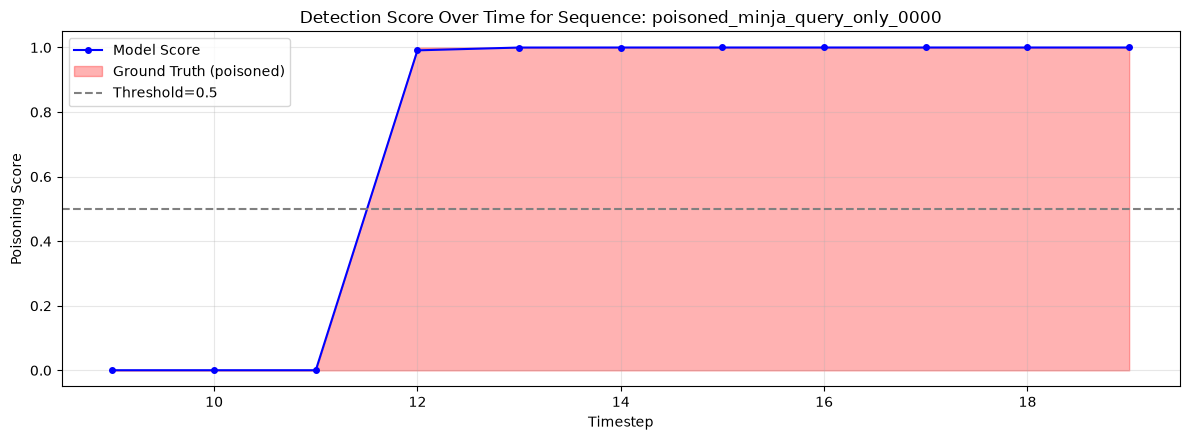

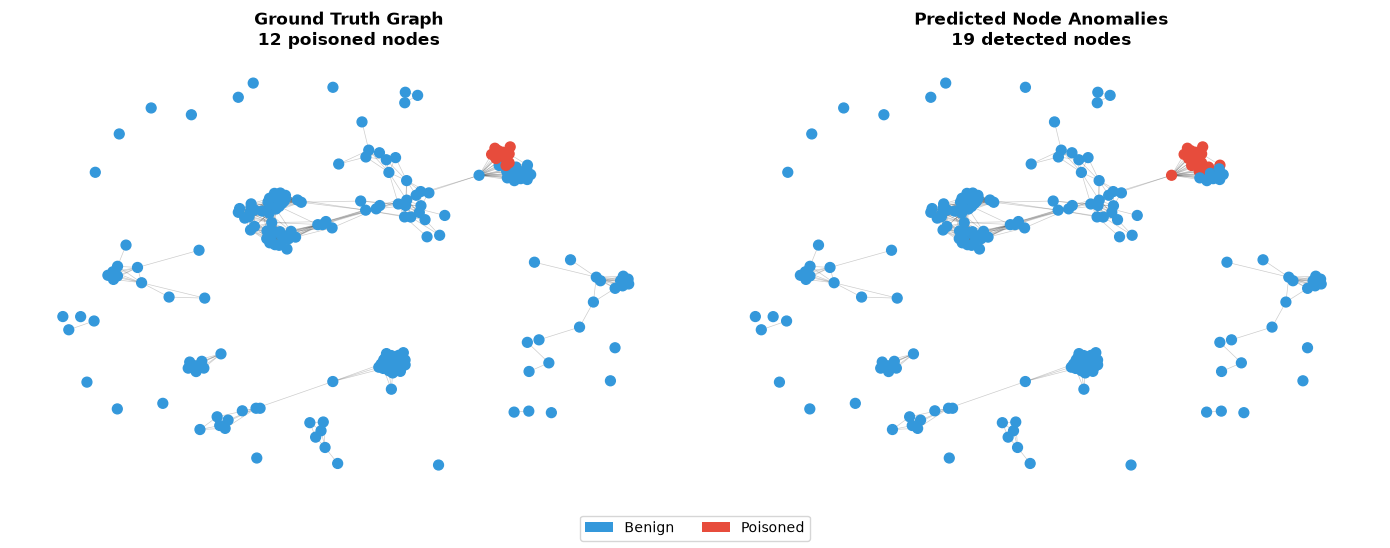

In [7]:
def load_snapshot(path):
    data = np.load(path)
    return {k: data[k] for k in data.files}

def snapshot_to_pyg(snap):
    edge_weights = torch.tensor(snap["edge_weights"], dtype=torch.float32)
    edge_attr = edge_weights.unsqueeze(-1) if edge_weights.numel() > 0 else torch.zeros((0, 1))
    return Data(
        x=torch.tensor(snap["node_features"], dtype=torch.float32),
        edge_index=torch.tensor(snap["edge_index"], dtype=torch.long),
        edge_attr=edge_attr,
        node_labels=torch.tensor(snap["node_labels"], dtype=torch.long),
        node_ids=torch.arange(snap["node_features"].shape[0], dtype=torch.long),
    )

def snapshot_to_networkx(snap):
    G = nx.Graph()
    for i in range(snap["node_features"].shape[0]):
        G.add_node(i, poisoned=int(snap["node_labels"][i]))
    edge_index = snap["edge_index"]
    if edge_index.shape[1] > 0:
        for idx in range(0, edge_index.shape[1], 2):
            G.add_edge(int(edge_index[0, idx]), int(edge_index[1, idx]))
    return G

# Pick sample poisoned sequence from metadata
with open(DATA_DIR / "metadata.json") as f:
    metadata = json.load(f)

poisoned_meta = [m for m in metadata if m["label"] == "poisoned"][0]
seq_id = poisoned_meta["sequence_id"]
print(f"Analyzing sequence: {seq_id} (Attack: {poisoned_meta.get('attack_type', 'unknown')})")

T = CONFIG["training"]["temporal_window"]
snapshots = sorted((DATA_DIR / seq_id).glob("snapshot_*.npz"))

graph_scores = []
ground_truth = []

eval_model = TGNDetector(CONFIG).to(device)
eval_model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
eval_model.eval()

eval_model.reset_memory()
with torch.no_grad():
    for start in range(len(snapshots) - T + 1):
        window = [load_snapshot(snapshots[i]) for i in range(start, start + T)]
        graphs = [Batch.from_data_list([snapshot_to_pyg(s)]).to(device) for s in window]
        score, _ = eval_model(graphs)
        graph_scores.append(score.item())
        ground_truth.append(window[-1]["graph_label"][0])

# 1. Plot Score Over Time
fig, ax = plt.subplots(figsize=(12, 4.5))
timesteps = range(T-1, T-1 + len(graph_scores))
ax.plot(timesteps, graph_scores, "b-o", label="Model Score", markersize=4)
ax.fill_between(timesteps, 0, ground_truth, alpha=0.3, color="red", label="Ground Truth (poisoned)")
ax.axhline(y=0.5, color="gray", linestyle="--", label="Threshold=0.5")

ax.set_xlabel("Timestep")
ax.set_ylabel("Poisoning Score")
ax.set_title(f"Detection Score Over Time for Sequence: {seq_id}")
ax.legend()
ax.set_ylim([-0.05, 1.05])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(IMG_DIR / "single_sequence_detection_score.png", dpi=300)
plt.show()

# 2. Node Graph Overlay Visualization
last_window = [load_snapshot(snapshots[i]) for i in range(len(snapshots)-T, len(snapshots))]
graphs = [Batch.from_data_list([snapshot_to_pyg(s)]).to(device) for s in last_window]

eval_model.reset_memory()
with torch.no_grad():
    _, node_scores = eval_model(graphs)

node_scores = node_scores.cpu().numpy()
node_labels = last_window[-1]["node_labels"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

G = snapshot_to_networkx(last_window[-1])
pos = nx.spring_layout(G, seed=42, k=2.0/np.sqrt(max(1, len(G.nodes))))
colors_gt = ["#e74c3c" if node_labels[n] == 1 else "#3498db" for n in G.nodes]
nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.2, width=0.5)
nx.draw_networkx_nodes(G, pos, ax=axes[0], node_color=colors_gt, node_size=50)
axes[0].set_title(f"Ground Truth Graph\n{int(node_labels.sum())} poisoned nodes", fontweight="bold")
axes[0].axis("off")

min_len = min(len(node_scores), len(G.nodes))
colors_pred = ["#e74c3c" if node_scores[n] > 0.54 else "#3498db" for n in range(min_len)]
nx.draw_networkx_edges(G, pos, ax=axes[1], alpha=0.2, width=0.5)
nx.draw_networkx_nodes(G, pos, ax=axes[1], node_color=colors_pred, node_size=50)
axes[1].set_title(f"Predicted Node Anomalies\n{(node_scores[:min_len] > 0.54).sum()} detected nodes", fontweight="bold")
axes[1].axis("off")

legend = [Patch(facecolor="#3498db", label="Benign"), Patch(facecolor="#e74c3c", label="Poisoned")]
fig.legend(handles=legend, loc="lower center", ncol=2)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(IMG_DIR / "node_graph_overlay.png", dpi=300)
plt.show()

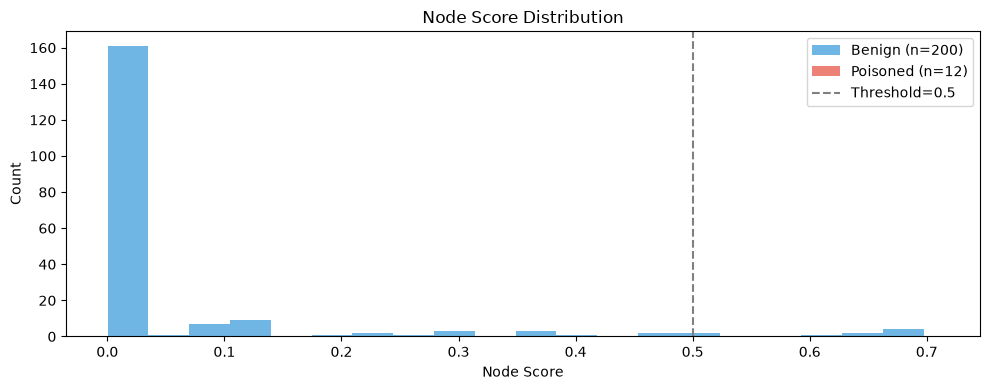

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))

benign_scores = node_scores[node_labels == 0]
poisoned_scores = node_scores[node_labels == 1]

ax.hist(benign_scores, bins=20, alpha=0.7, label=f"Benign (n={len(benign_scores)})", color="#3498db")
ax.hist(poisoned_scores, bins=20, alpha=0.7, label=f"Poisoned (n={len(poisoned_scores)})", color="#e74c3c")
ax.axvline(x=0.5, color="gray", linestyle="--", label="Threshold=0.5")
ax.set_xlabel("Node Score")
ax.set_ylabel("Count")
ax.set_title("Node Score Distribution")
ax.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / "node_score_distribution.png", dpi=300)
plt.show()


In [9]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(node_labels, node_scores[:len(node_labels)])
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"Optimal node threshold: {best_threshold:.3f}")
print(f"At this threshold: Precision={precisions[best_idx]:.3f}, Recall={recalls[best_idx]:.3f}, F1={f1_scores[best_idx]:.3f}")


Optimal node threshold: 0.710
At this threshold: Precision=1.000, Recall=1.000, F1=1.000


In [10]:
# After running evaluation, analyze errors:

# Graph-level errors
graph_preds = (np.array(graph_scores) > 0.5).astype(int)
graph_labels = np.array(ground_truth)

false_positives = ((graph_preds == 1) & (graph_labels == 0)).sum()
false_negatives = ((graph_preds == 0) & (graph_labels == 1)).sum()
true_positives = ((graph_preds == 1) & (graph_labels == 1)).sum()
true_negatives = ((graph_preds == 0) & (graph_labels == 0)).sum()

print("=== Graph-Level Confusion Matrix ===")
print(f"True Positives:  {true_positives}")
print(f"True Negatives:  {true_negatives}")
print(f"False Positives: {false_positives} (clean predicted as poisoned)")
print(f"False Negatives: {false_negatives} (poisoned predicted as clean)")


=== Graph-Level Confusion Matrix ===
True Positives:  8
True Negatives:  3
False Positives: 0 (clean predicted as poisoned)
False Negatives: 0 (poisoned predicted as clean)


## 1. Load Evaluation Results

In [11]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path



In [12]:
with open(EXP_DIR / "eval_results.json") as f:
    results = json.load(f)

graph = results["graph_level"]
node = results["node_level"]
latency = results["detection_latency"]

## 2. Graph-Level Detection Metrics

In [13]:
print("Graph-Level Detection (Is this trajectory poisoned?)")
print("=" * 50)
print(f"AUROC:              {graph['auroc']:.4f}")
print(f"Average Precision:  {graph['average_precision']:.4f}")
print(f"F1 @ threshold=0.5: {graph['f1_at_0.5']:.4f}")
print(f"Best F1:            {graph['best_f1']:.4f} (threshold={graph['best_threshold']:.4f})")
print(f"FPR @ TPR=0.9:      {graph['fpr_at_tpr_0.9']:.4f}")

Graph-Level Detection (Is this trajectory poisoned?)
AUROC:              1.0000
Average Precision:  1.0000
F1 @ threshold=0.5: 0.9822
Best F1:            1.0000 (threshold=0.0006)
FPR @ TPR=0.9:      0.0000


## 3. Node-Level Detection Metrics

In [14]:
print("Node-Level Detection (Which memory records are poisoned?)")
print("=" * 50)
print(f"AUROC:              {node['node_auroc']:.4f}")
print(f"Average Precision:  {node['node_average_precision']:.4f}")

Node-Level Detection (Which memory records are poisoned?)
AUROC:              0.9737
Average Precision:  0.6337


## 4. Detection Latency

In [17]:
print("Detection Latency (How fast do we detect poisoning?)")
print("=" * 50)
print(f"Mean latency:   {latency['mean_detection_latency']:.2f} snapshots")
print(f"Median latency: {latency['median_detection_latency']:.1f} snapshots")
print(f"Std deviation:  {latency['std_detection_latency']:.2f}")
print(f"Min latency:    {latency['min_detection_latency']} snapshots")
print(f"Max latency:    {latency['max_detection_latency']} snapshots")

Detection Latency (How fast do we detect poisoning?)
Mean latency:   1.55 snapshots
Median latency: 1.0 snapshots
Std deviation:  1.29
Min latency:    0 snapshots
Max latency:    4 snapshots


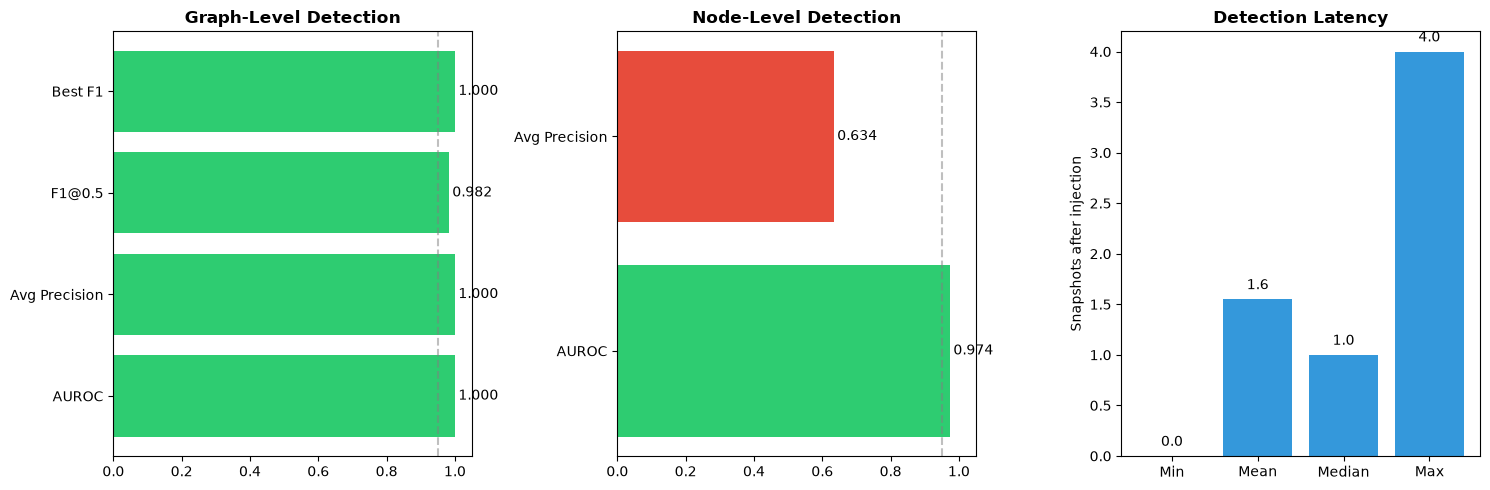

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Graph-level metrics
metrics = ["AUROC", "Avg Precision", "F1@0.5", "Best F1"]
values = [graph["auroc"], graph["average_precision"], graph["f1_at_0.5"], graph["best_f1"]]
colors = ["#2ecc71" if v > 0.95 else "#f39c12" if v > 0.8 else "#e74c3c" for v in values]
axes[0].barh(metrics, values, color=colors)
axes[0].set_xlim([0, 1.05])
axes[0].set_title("Graph-Level Detection", fontweight="bold")
axes[0].axvline(x=0.95, color="gray", linestyle="--", alpha=0.5)
for i, v in enumerate(values):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va="center")

# Node-level metrics
metrics_n = ["AUROC", "Avg Precision"]
values_n = [node["node_auroc"], node["node_average_precision"]]
colors_n = ["#2ecc71" if v > 0.95 else "#f39c12" if v > 0.8 else "#e74c3c" for v in values_n]
axes[1].barh(metrics_n, values_n, color=colors_n)
axes[1].set_xlim([0, 1.05])
axes[1].set_title("Node-Level Detection", fontweight="bold")
axes[1].axvline(x=0.95, color="gray", linestyle="--", alpha=0.5)
for i, v in enumerate(values_n):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va="center")

# Detection latency
latency_vals = [latency["min_detection_latency"], latency["mean_detection_latency"], 
                latency["median_detection_latency"], latency["max_detection_latency"]]
latency_labels = ["Min", "Mean", "Median", "Max"]
axes[2].bar(latency_labels, latency_vals, color="#3498db")
axes[2].set_ylabel("Snapshots after injection")
axes[2].set_title("Detection Latency", fontweight="bold")
for i, v in enumerate(latency_vals):
    axes[2].text(i, v + 0.1, f"{v:.1f}", ha="center")

plt.tight_layout()
plt.savefig(IMG_DIR / "metrics_summary_bars.png", dpi=300)
plt.show()

In [19]:
## 6. Summary Table

In [20]:
print("\n" + "="*60)
print("SUMMARY: TGN Memory Poisoning Detector Performance")
print("="*60)
print(f"{'Metric':<30} {'Value':<15} {'Status'}")
print("-"*60)
print(f"{'Graph AUROC':<30} {graph['auroc']:.4f}{'':>9} {'✓ Excellent' if graph['auroc'] > 0.99 else ''}")
print(f"{'Graph F1':<30} {graph['best_f1']:.4f}{'':>9} {'✓ Excellent' if graph['best_f1'] > 0.99 else ''}")
print(f"{'Node AUROC':<30} {node['node_auroc']:.4f}{'':>9} {'✓ Good' if node['node_auroc'] > 0.95 else ''}")
print(f"{'Mean Detection Latency':<30} {latency['mean_detection_latency']:.1f} snaps{'':>4} {'✓ Fast' if latency['mean_detection_latency'] < 3 else ''}")
print("="*60)


SUMMARY: TGN Memory Poisoning Detector Performance
Metric                         Value           Status
------------------------------------------------------------
Graph AUROC                    1.0000          ✓ Excellent
Graph F1                       1.0000          ✓ Excellent
Node AUROC                     0.9737          ✓ Good
Mean Detection Latency         1.6 snaps     ✓ Fast
